In [ ]:
#This is the original code I used to download LIGO BRS data. I made it in a Jupyter notebook because I (foolishly) didn't quite understand the scope and amount of data wanted so I just kept trying to build on the quick code I wrote to pull a couple of channels 
#The hardest part was actually getting everything formated correctly so that the LIGO server would reconize it and call the right data, but after getting all that figured it it's not too complicated of a system
#For getting the file name from the LIGO standard (i.e. 'L1:ISI-GND_BRS_ETMX_RY_OUT_DQ') I just manually titled everything to (hopefully) match the seismology standard

In [10]:
from gwpy.timeseries import TimeSeries
import numpy as np
from gwpy.plot import Plot
from gwpy.frequencyseries import FrequencySeries
from gwpy.astro import inspiral_range
import pandas as pd
from gwpy.time import tconvert
from gwpy.time import to_gps
from gwpy.plot import Plot
import matplotlib.pyplot as plt

In [2]:
StartingTimeString='Sep 15 2024 22:22:48.000'
HTRUE=1
LTRUE=1
dt = 60*60*1

In [3]:
starttime=to_gps(StartingTimeString)
StartingTimeString=StartingTimeString.replace(" ", "_")
StartingTimeString=StartingTimeString.replace(":", "-")
StartingTimeString=StartingTimeString.replace(".", "-")

In [4]:
L1_SEI_ITMX=['L1:ISI-GND_STS_ITMX_X_DQ','L1:ISI-GND_STS_ITMX_Y_DQ','L1:ISI-GND_STS_ITMX_Z_DQ']
L1_SEI_ITMY=['L1:ISI-GND_STS_ITMY_X_DQ','L1:ISI-GND_STS_ITMY_Y_DQ','L1:ISI-GND_STS_ITMY_Z_DQ']
L1_SEI_ETMX=['L1:ISI-GND_STS_ETMX_X_DQ','L1:ISI-GND_STS_ETMX_Y_DQ','L1:ISI-GND_STS_ETMX_Z_DQ']
L1_SEI_ETMY=['L1:ISI-GND_STS_ETMY_X_DQ','L1:ISI-GND_STS_ETMY_Y_DQ','L1:ISI-GND_STS_ETMY_Z_DQ']

L1_BRS_ETMX=['L1:ISI-GND_BRS_ETMX_RY_OUT_DQ']
L1_BRS_ETMY=['L1:ISI-GND_BRS_ETMY_RX_OUT_DQ']
L1_BRS_ITMX=['L1:ISI-GND_BRS_ITMX_RY_OUT_DQ']
L1_BRS_ITMY=['L1:ISI-GND_BRS_ITMY_RX_OUT_DQ']

Livingston data saved


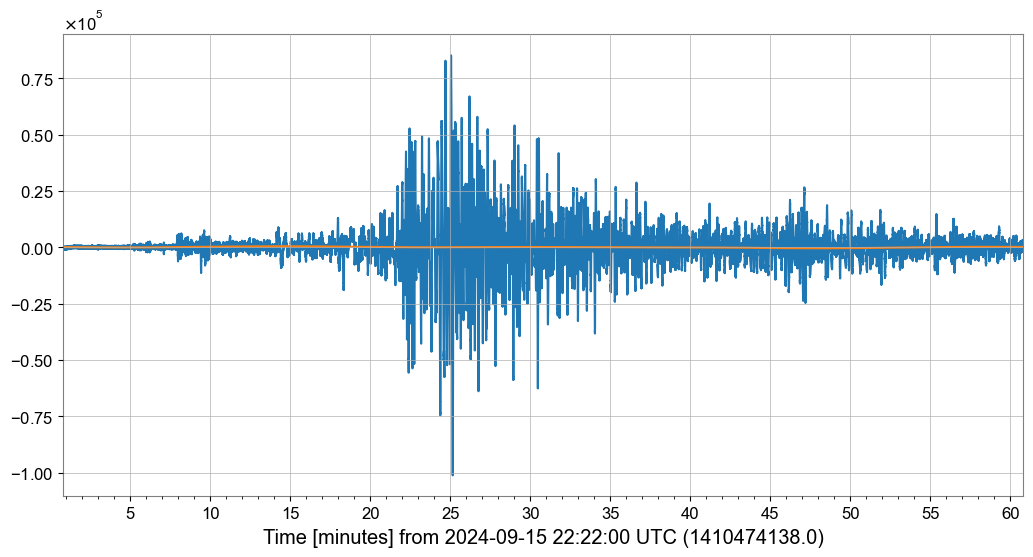

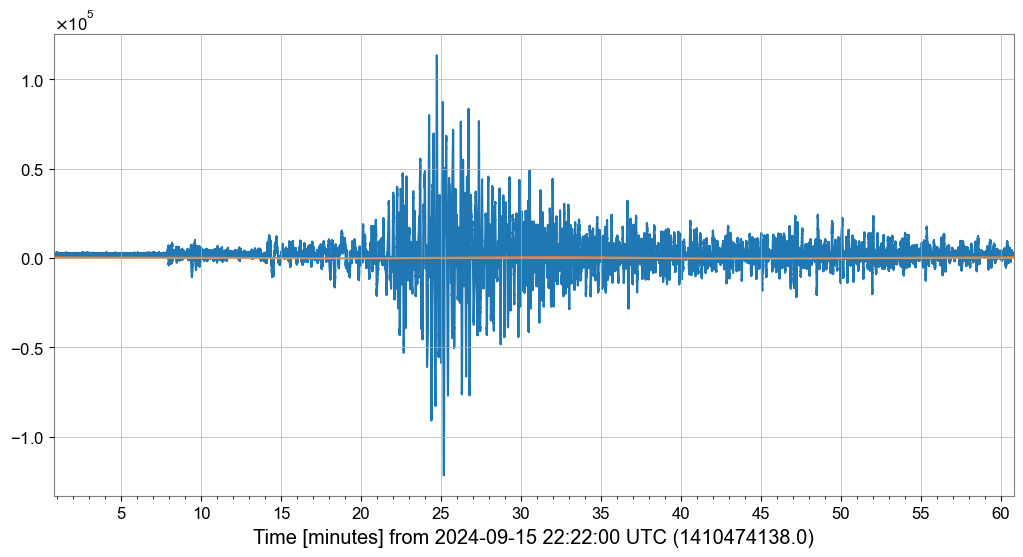

In [12]:
df_SEIITMX_X_Data=pd.DataFrame()
df_LB_ETMX=pd.DataFrame()
df_LB_ETMY=pd.DataFrame()
df_LB_ITMX=pd.DataFrame()
df_LB_ITMY=pd.DataFrame()
df_SEIITMX_Y_Data=pd.DataFrame()
df_SEIITMX_Z_Data=pd.DataFrame()
df_SEIITMY_X_Data=pd.DataFrame()
df_SEIITMY_Y_Data=pd.DataFrame()
df_SEIITMY_Z_Data=pd.DataFrame()
df_SEIETMX_X_Data=pd.DataFrame()
df_SEIETMX_Y_Data=pd.DataFrame()
df_SEIETMX_Z_Data=pd.DataFrame()
df_SEIETMY_X_Data=pd.DataFrame()
df_SEIETMY_Y_Data=pd.DataFrame()
df_SEIETMY_Z_Data=pd.DataFrame()
if LTRUE==1:

    L1_BRS_ETMX_Data = TimeSeries.fetch(L1_BRS_ETMX[0],starttime, starttime+dt)
    L1_BRS_ETMY_Data = TimeSeries.fetch(L1_BRS_ETMY[0],starttime, starttime+dt)
    L1_BRS_ITMX_Data = TimeSeries.fetch(L1_BRS_ITMX[0],starttime, starttime+dt)
    L1_BRS_ITMY_Data = TimeSeries.fetch(L1_BRS_ITMY[0],starttime, starttime+dt)

    df_LB_ETMX = pd.DataFrame(data=L1_BRS_ETMX_Data)
    df_LB_ETMY = pd.DataFrame(data=L1_BRS_ETMY_Data)
    df_LB_ITMX = pd.DataFrame(data=L1_BRS_ITMX_Data)
    df_LB_ITMY = pd.DataFrame(data=L1_BRS_ITMY_Data)

    SEIITMX_X_Data = TimeSeries.fetch(L1_SEI_ITMX[0],starttime, starttime+dt)
    SEIITMX_Y_Data = TimeSeries.fetch(L1_SEI_ITMX[1],starttime, starttime+dt)
    SEIITMX_Z_Data = TimeSeries.fetch(L1_SEI_ITMX[2],starttime, starttime+dt)
    SEIITMY_X_Data = TimeSeries.fetch(L1_SEI_ITMY[0],starttime, starttime+dt)
    SEIITMY_Y_Data = TimeSeries.fetch(L1_SEI_ITMY[1],starttime, starttime+dt)
    SEIITMY_Z_Data = TimeSeries.fetch(L1_SEI_ITMY[2],starttime, starttime+dt)

    SEIETMX_X_Data = TimeSeries.fetch(L1_SEI_ETMX[0],starttime, starttime+dt)
    SEIETMX_Y_Data = TimeSeries.fetch(L1_SEI_ETMX[1],starttime, starttime+dt)
    SEIETMX_Z_Data = TimeSeries.fetch(L1_SEI_ETMX[2],starttime, starttime+dt)
    SEIETMY_X_Data = TimeSeries.fetch(L1_SEI_ETMY[0],starttime, starttime+dt)
    SEIETMY_Y_Data = TimeSeries.fetch(L1_SEI_ETMY[1],starttime, starttime+dt)
    SEIETMY_Z_Data = TimeSeries.fetch(L1_SEI_ETMY[2],starttime, starttime+dt)

    df_SEIITMX_X_Data = pd.DataFrame(data=SEIITMX_X_Data)
    df_SEIITMX_Y_Data = pd.DataFrame(data=SEIITMX_Y_Data)
    df_SEIITMX_Z_Data = pd.DataFrame(data=SEIITMX_Z_Data)
    df_SEIITMY_X_Data = pd.DataFrame(data=SEIITMY_X_Data)
    df_SEIITMY_Y_Data = pd.DataFrame(data=SEIITMY_Y_Data)
    df_SEIITMY_Z_Data = pd.DataFrame(data=SEIITMY_Z_Data)
    df_SEIETMX_X_Data = pd.DataFrame(data=SEIETMX_X_Data)
    df_SEIETMX_Y_Data = pd.DataFrame(data=SEIETMX_Y_Data)
    df_SEIETMX_Z_Data = pd.DataFrame(data=SEIETMX_Z_Data)
    df_SEIETMY_X_Data = pd.DataFrame(data=SEIETMY_X_Data)
    df_SEIETMY_Y_Data = pd.DataFrame(data=SEIETMY_Y_Data)
    df_SEIETMY_Z_Data = pd.DataFrame(data=SEIETMY_Z_Data)

    df_LB_ETMX.to_csv("LIV_EW_DJ2_"+StartingTimeString+"_256.csv")
    df_LB_ETMY.to_csv("LIV_ES_DJ1_"+StartingTimeString+"_256.csv")
    df_LB_ITMX.to_csv("LIV_IW_DJ2_"+StartingTimeString+"_256.csv")
    df_LB_ITMY.to_csv("LIV_IS_DJ1_"+StartingTimeString+"_256.csv")
    
    df_SEIITMX_X_Data.to_csv("LIV_IW_DH2_"+StartingTimeString+"_512.csv")
    df_SEIITMX_Y_Data.to_csv("LIV_IW_DH3_"+StartingTimeString+"_512.csv")
    df_SEIITMX_Z_Data.to_csv("LIV_IW_DH1_"+StartingTimeString+"_512.csv")
    
    df_SEIITMY_X_Data.to_csv("LIV_IS_DH2_"+StartingTimeString+"_512.csv")
    df_SEIITMY_Y_Data.to_csv("LIV_IS_DH3_"+StartingTimeString+"_512.csv")
    df_SEIITMY_Z_Data.to_csv("LIV_IS_DH1_"+StartingTimeString+"_512.csv")

    df_SEIETMX_X_Data.to_csv("LIV_EW_DH2_"+StartingTimeString+"_512.csv")
    df_SEIETMX_Y_Data.to_csv("LIV_EW_DH3_"+StartingTimeString+"_512.csv")
    df_SEIETMX_Z_Data.to_csv("LIV_EW_DH1_"+StartingTimeString+"_512.csv")

    df_SEIETMY_X_Data.to_csv("LIV_ES_DH2_"+StartingTimeString+"_512.csv")
    df_SEIETMY_Y_Data.to_csv("LIV_ES_DH3_"+StartingTimeString+"_512.csv")
    df_SEIETMY_Z_Data.to_csv("LIV_ES_DH1_"+StartingTimeString+"_512.csv")
    print("Livingston data saved")

    plot=Plot(SEIETMX_Z_Data.bandpass(.01,30),L1_BRS_ETMX_Data.detrend())
    plt.show()
    plot=Plot(SEIETMY_Z_Data.lowpass(50),L1_BRS_ETMY_Data)
    plt.show()

else:
    print("No Livingston data")

In [14]:
H1_SEI_ETMX=['H1:ISI-GND_STS_ETMX_X_DQ','H1:ISI-GND_STS_ETMX_Y_DQ','H1:ISI-GND_STS_ETMX_Z_DQ']
H1_SEI_ETMY=['H1:ISI-GND_STS_ETMY_X_DQ','H1:ISI-GND_STS_ETMY_Y_DQ','H1:ISI-GND_STS_ETMY_Z_DQ']
H1_SEI_ITMY=['H1:ISI-GND_STS_ITMY_X_DQ','H1:ISI-GND_STS_ITMY_Y_DQ','H1:ISI-GND_STS_ITMY_Z_DQ']

H1_BRS_ETMX=['H1:ISI-GND_BRS_ETMX_RY_OUT_DQ']
H1_BRS_ETMY=['H1:ISI-GND_BRS_ETMY_RX_OUT_DQ']
VAULT=['H1:PEM-VAULT_SEIS_1030X195Y_STS2_X_DQ','H1:PEM-VAULT_SEIS_1030X195Y_STS2_Y_DQ']

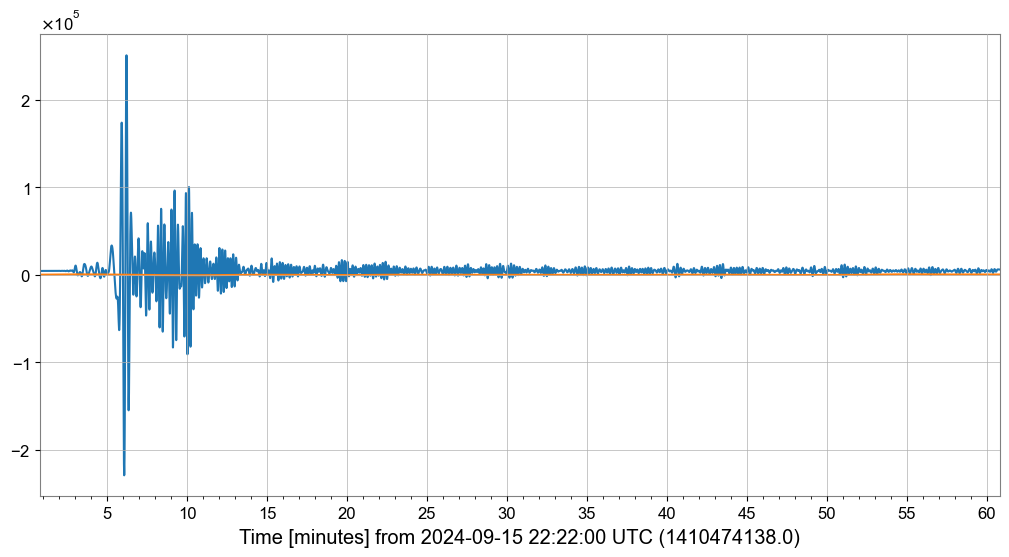

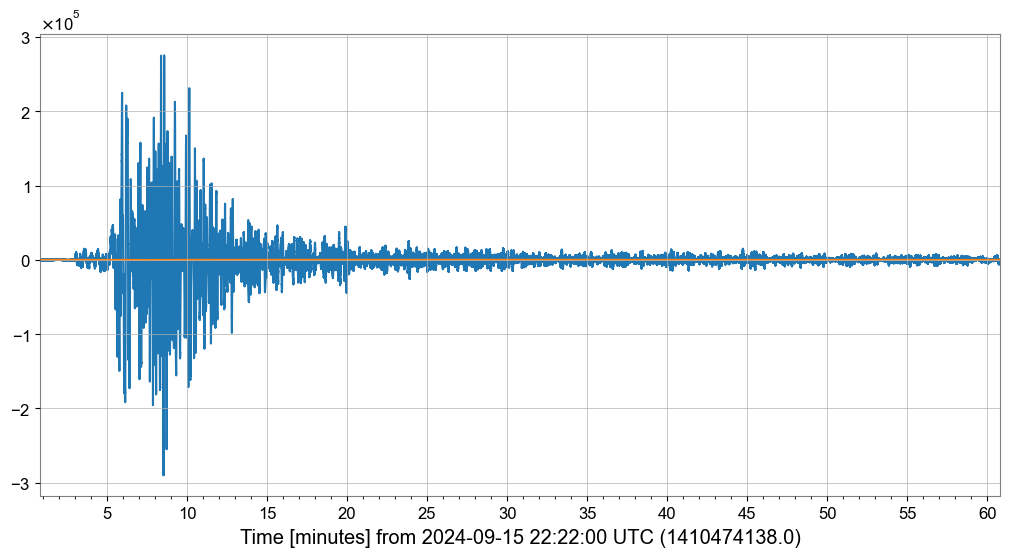

Hanford data saved


In [16]:
df_H1_BRS_ETMX_Data=pd.DataFrame()
df_H1_BRS_ETMY_Data=pd.DataFrame()
dfVX=pd.DataFrame()
dfVY=pd.DataFrame()
df_H1_SEIETMY_X_Data=pd.DataFrame()
df_H1_SEIETMY_Y_Data=pd.DataFrame()
df_H1_SEIETMY_Z_Data=pd.DataFrame()
df_H1_SEIETMX_X_Data=pd.DataFrame()
df_H1_SEIETMX_Y_Data=pd.DataFrame()
df_H1_SEIETMX_Z_Data=pd.DataFrame()
df_H1_SEIITMY_X_Data=pd.DataFrame()
df_H1_SEIITMY_Y_Data=pd.DataFrame()
df_H1_SEIITMY_Z_Data=pd.DataFrame()

if HTRUE==1:

    H1_SEIETMX_X_Data = TimeSeries.fetch(H1_SEI_ETMX[0],starttime, starttime+dt)
    H1_SEIETMX_Y_Data = TimeSeries.fetch(H1_SEI_ETMX[1],starttime, starttime+dt)
    H1_SEIETMX_Z_Data = TimeSeries.fetch(H1_SEI_ETMX[2],starttime, starttime+dt)
    H1_SEIETMY_X_Data = TimeSeries.fetch(H1_SEI_ETMY[0],starttime, starttime+dt)
    H1_SEIETMY_Y_Data = TimeSeries.fetch(H1_SEI_ETMY[1],starttime, starttime+dt)
    H1_SEIETMY_Z_Data = TimeSeries.fetch(H1_SEI_ETMY[2],starttime, starttime+dt) 
    H1_SEIITMY_X_Data = TimeSeries.fetch(H1_SEI_ITMY[0],starttime, starttime+dt)
    H1_SEIITMY_Y_Data = TimeSeries.fetch(H1_SEI_ITMY[1],starttime, starttime+dt)
    H1_SEIITMY_Z_Data = TimeSeries.fetch(H1_SEI_ITMY[2],starttime, starttime+dt)
    
    df_H1_SEIETMY_X_Data = pd.DataFrame(data=H1_SEIETMY_X_Data)
    df_H1_SEIETMY_Y_Data = pd.DataFrame(data=H1_SEIETMY_Y_Data)
    df_H1_SEIETMY_Z_Data = pd.DataFrame(data=H1_SEIETMY_Z_Data)

    df_H1_SEIETMX_X_Data = pd.DataFrame(data=H1_SEIETMX_X_Data)
    df_H1_SEIETMX_Y_Data = pd.DataFrame(data=H1_SEIETMX_Y_Data)
    df_H1_SEIETMX_Z_Data = pd.DataFrame(data=H1_SEIETMX_Z_Data)

    df_H1_SEIITMY_X_Data = pd.DataFrame(data=H1_SEIITMY_X_Data)
    df_H1_SEIITMY_Y_Data = pd.DataFrame(data=H1_SEIITMY_Y_Data)
    df_H1_SEIITMY_Z_Data = pd.DataFrame(data=H1_SEIITMY_Z_Data)

    df_H1_SEIETMY_X_Data.to_csv("HAN_ES_DH2_"+StartingTimeString+"_512.csv")
    df_H1_SEIETMY_Y_Data.to_csv("HAN_ES_DH3_"+StartingTimeString+"_512.csv")
    df_H1_SEIETMY_Z_Data.to_csv("HAN_ES_DH1_"+StartingTimeString+"_512.csv")

    df_H1_SEIETMX_X_Data.to_csv("HAN_EN_DH2_"+StartingTimeString+"_512.csv")
    df_H1_SEIETMX_Y_Data.to_csv("HAN_EN_DH3_"+StartingTimeString+"_512.csv")
    df_H1_SEIETMX_Z_Data.to_csv("HAN_EN_DH1_"+StartingTimeString+"_512.csv")

    df_H1_SEIITMY_X_Data.to_csv("HAN_IS_DH2_"+StartingTimeString+"_512.csv")
    df_H1_SEIITMY_Y_Data.to_csv("HAN_IS_DH3_"+StartingTimeString+"_512.csv")
    df_H1_SEIITMY_Z_Data.to_csv("HAN_IS_DH1_"+StartingTimeString+"_512.csv")

    H1_BRS_ETMX_Data = TimeSeries.fetch(H1_BRS_ETMX[0],starttime, starttime+dt)
    H1_BRS_ETMY_Data = TimeSeries.fetch(H1_BRS_ETMY[0],starttime, starttime+dt)
    VAULTDataX = TimeSeries.fetch(VAULT[0],starttime, starttime+dt)
    VAULTDataY = TimeSeries.fetch(VAULT[1],starttime, starttime+dt)

    df_H1_BRS_ETMX_Data = pd.DataFrame(data=H1_BRS_ETMX_Data)
    df_H1_BRS_ETMY_Data = pd.DataFrame(data=H1_BRS_ETMY_Data)
    dfVX = pd.DataFrame(data=VAULTDataX)
    dfVY = pd.DataFrame(data=VAULTDataY)

    df_H1_BRS_ETMY_Data.to_csv("HAN_ES_DJ1_"+StartingTimeString+"_256.csv")

    df_H1_BRS_ETMX_Data.to_csv("HAN_EN_DJ2_"+StartingTimeString+"_256.csv")

    dfVX.to_csv("HAN_VA_HHN_"+StartingTimeString+"_256.csv")
    dfVY.to_csv("HAN_VA_HHE_"+StartingTimeString+"_256.csv")
    
    plot=Plot(H1_SEIETMX_Z_Data.lowpass(.1),H1_BRS_ETMX_Data)
    plt.show()
    plot=Plot(H1_SEIETMY_Z_Data.bandpass(.01,30),H1_BRS_ETMY_Data)
    plt.show()
    print("Hanford data saved")
else:
    print("No Hanford Data")